##**Partie 2 : Mini-Projet - Prédiction des Maladies Cardiaques**

*Module :* Technologies IA  
*Réalisé par :* Safae BOUZIANE WARITINI  N° : 8 (ILIA2)

**Présentation du Dataset** :

*   **Nom du dataset :** Heart Disease Dataset (disponible sur Kaggle).
*   **Objectif du projet :** Prédire si un patient est atteint ou non d'une maladie cardiaque (target : 0 = Sain, 1 = Malade) en utilisant un ensemble de caractéristiques cliniques et démographiques (âge, sexe, tension artérielle, cholestérol, etc.).


In [1]:
# Importation des bibliothèques nécessaires
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Configuration graphique
sns.set_theme(style="whitegrid")
print("Bibliothèques importées avec succès !")

Bibliothèques importées avec succès !


##Étape 1 : Chargement et Exploration des Données (EDA)

L'exploration des données (Exploratory Data Analysis) permet de comprendre la structure du jeu de données, d'identifier les types de variables (numériques ou catégorielles) et de repérer d'éventuelles anomalies ou valeurs manquantes.

In [2]:
# Chargement du fichier CSV
url = "https://raw.githubusercontent.com/SafaeBouzianeWaritini/TP-Technologies-IA/refs/heads/main/TP1-Technologies-IA/heart_disease_uci.csv"
df = pd.read_csv(url)

# Affichage des premières lignes
print("--- Aperçu des données ---")
display(df.head())

# Informations structurelles
print("\n--- Informations générales ---")
df.info()

# Statistiques descriptives
print("\n--- Statistiques descriptives ---")
display(df.describe())

--- Aperçu des données ---


,id,age,sex,dataset,cp,trestbps,chol,fbs,restecg,thalch,exang,oldpeak,slope,ca,thal,num
0,1,63,Male,Cleveland,typical angina,145.0,233.0,True,lv hypertrophy,150.0,False,2.3,downsloping,0.0,fixed defect,0
1,2,67,Male,Cleveland,asymptomatic,160.0,286.0,False,lv hypertrophy,108.0,True,1.5,flat,3.0,normal,2
2,3,67,Male,Cleveland,asymptomatic,120.0,229.0,False,lv hypertrophy,129.0,True,2.6,flat,2.0,reversable defect,1
3,4,37,Male,Cleveland,non-anginal,130.0,250.0,False,normal,187.0,False,3.5,downsloping,0.0,normal,0
4,5,41,Female,Cleveland,atypical angina,130.0,204.0,False,lv hypertrophy,172.0,False,1.4,upsloping,0.0,normal,0



--- Informations générales ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 920 entries, 0 to 919
Data columns (total 16 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   id        920 non-null    int64  
 1   age       920 non-null    int64  
 2   sex       920 non-null    object 
 3   dataset   920 non-null    object 
 4   cp        920 non-null    object 
 5   trestbps  861 non-null    float64
 6   chol      890 non-null    float64
 7   fbs       830 non-null    object 
 8   restecg   918 non-null    object 
 9   thalch    865 non-null    float64
 10  exang     865 non-null    object 
 11  oldpeak   858 non-null    float64
 12  slope     611 non-null    object 
 13  ca        309 non-null    float64
 14  thal      434 non-null    object 
 15  num       920 non-null    int64  
dtypes: float64(5), int64(3), object(8)
memory usage: 115.1+ KB

--- Statistiques descriptives ---


,id,age,trestbps,chol,thalch,oldpeak,ca,num
count,920.000000,920.000000,861.000000,890.000000,865.000000,858.000000,309.000000,920.000000
mean,460.500000,53.510870,132.132404,199.130337,137.545665,0.878788,0.676375,0.995652
std,265.725422,9.424685,19.066070,110.780810,25.926276,1.091226,0.935653,1.142693
min,1.000000,28.000000,0.000000,0.000000,60.000000,-2.600000,0.000000,0.000000
25%,230.750000,47.000000,120.000000,175.000000,120.000000,0.000000,0.000000,0.000000
50%,460.500000,54.000000,130.000000,223.000000,140.000000,0.500000,0.000000,1.000000
75%,690.250000,60.000000,140.000000,268.000000,157.000000,1.500000,1.000000,2.000000
max,920.000000,77.000000,200.000000,603.000000,202.000000,6.200000,3.000000,4.000000


## Étape 2 : Nettoyage et Préparation des Données
Cette étape consiste à s'assurer de la propreté du jeu de données :
1. **Valeurs manquantes :** Vérifier si des lignes comportent des valeurs nulles.
2. **Doublons :** Supprimer les lignes dupliquées pour éviter tout biais lors de l'apprentissage des modèles.

In [3]:
# Vérification des valeurs manquantes
print("Valeurs manquantes par colonne :\n", df.isnull().sum())

# Suppression des doublons éventuels
print(f"Lignes avant suppression des doublons : {df.shape[0]}")
df = df.drop_duplicates()
print(f"Lignes après suppression des doublons  : {df.shape[0]}")

Valeurs manquantes par colonne :
 id            0
age           0
sex           0
dataset       0
cp            0
trestbps     59
chol         30
fbs          90
restecg       2
thalch       55
exang        55
oldpeak      62
slope       309
ca          611
thal        486
num           0
dtype: int64
Lignes avant suppression des doublons : 920
Lignes après suppression des doublons  : 920


## Étape 3 : Visualisation Graphique
Les graphiques ci-dessous permettent d'analyser l'équilibre de notre variable cible (`num`) et d'observer les corrélations linéaires entre les différentes mesures médicales.

/tmp/ipykernel_1072/2371832797.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='num', data=df, palette='Set2')


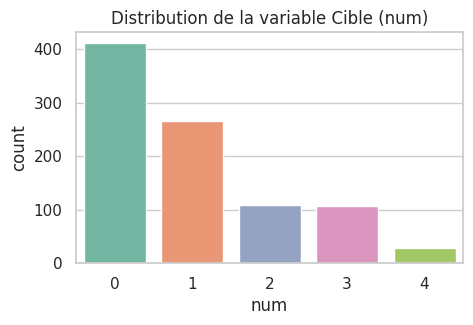

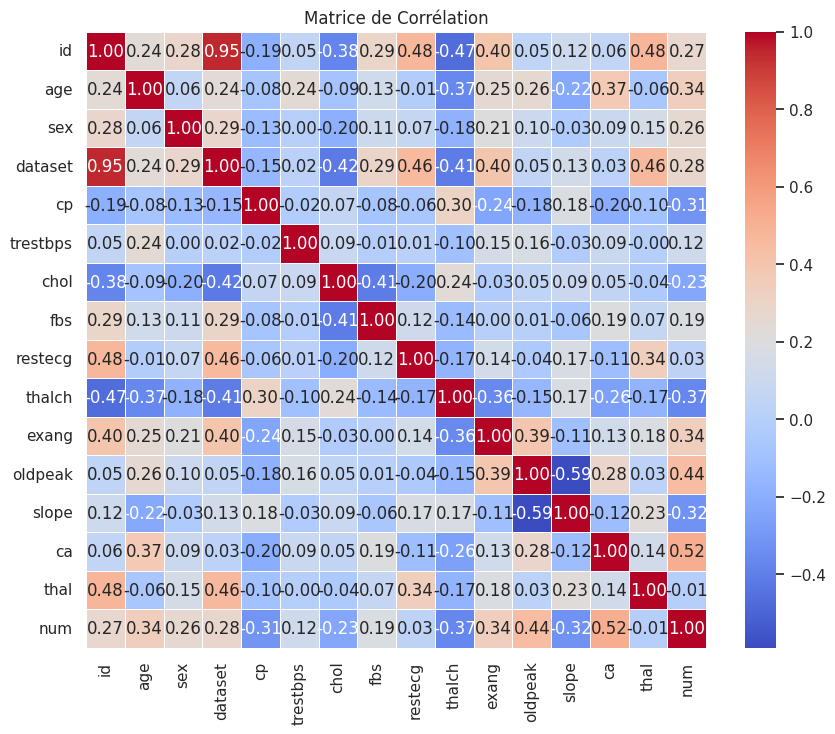

In [8]:
from sklearn.preprocessing import LabelEncoder

# 1. Distribution de la variable cible 'num'
plt.figure(figsize=(5, 3))
sns.countplot(x='num', data=df, palette='Set2')
plt.title('Distribution de la variable Cible (num)')
plt.show()

# Encodage de toutes les colonnes textuelles en valeurs numériques
le = LabelEncoder()
for col in df.select_dtypes(include=['object']).columns:
    df[col] = le.fit_transform(df[col])

# 2. Matrice de corrélation
plt.figure(figsize=(10, 8))
sns.heatmap(df.corr(), annot=True, fmt='.2f', cmap='coolwarm', linewidths=0.5)
plt.title('Matrice de Corrélation')
plt.show()

In [12]:
# Remplacer les valeurs manquantes par la médiane pour chaque colonne numérique
df = df.fillna(df.median(numeric_only=True))

# Vérification qu'il ne reste plus de NaN
print("Valeurs manquantes restantes :\n", df.isnull().sum())

Valeurs manquantes restantes :
 id          0
age         0
sex         0
dataset     0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalch      0
exang       0
oldpeak     0
slope       0
ca          0
thal        0
num         0
dtype: int64


## Étape 4 : Séparation des données et Standardisation
* **Train / Test Split :** Nous séparons les caractéristiques explicatives ($X$) de la variable à prédire ($y$), puis nous divisons les données (80% pour l'entraînement et 20% pour le test).
* **Standardisation :** Les algorithmes linéaires comme la Régression Logistique nécessitent que toutes les variables soient à la même échelle pour converger efficacement. Nous utilisons `StandardScaler`.

In [13]:
X = df.drop('num', axis=1)
y = df['num']

# Division 80% / 20%
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Standardisation
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"Taille de l'ensemble d'entraînement : {X_train.shape}")
print(f"Taille de l'ensemble de test      : {X_test.shape}")

Taille de l'ensemble d'entraînement : (736, 15)
Taille de l'ensemble de test      : (184, 15)


## Étape 5 : Entraînement des Modèles de Classification
Nous allons entraîner deux modèles distincts pour comparer leurs performances :
1. **Régression Logistique :** Un modèle linéaire simple servant de référence (*baseline*).
2. **Random Forest Classifier :** Un modèle par ensemble d'arbres de décision, réputé pour sa robustesse et sa capacité à capturer les relations non-linéaires.

In [14]:
# Instanciation et entraînement de la Régression Logistique (avec données standardisées)
lr_model = LogisticRegression(random_state=42, max_iter=1000)
lr_model.fit(X_train_scaled, y_train)

# Instanciation et entraînement du Random Forest (les arbres n'ont pas besoin de standardisation)
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)

print("Modèles entraînés avec succès !")

Modèles entraînés avec succès !


## Étape 6 : Évaluation et Comparaison des Modèles
Nous évaluons les modèles à l'aide de l'**Accuracy** (précision globale) et du **rapport de classification** (précision, rappel, score F1 pour chaque classe).

In [15]:
# Prédictions
y_pred_lr = lr_model.predict(X_test_scaled)
y_pred_rf = rf_model.predict(X_test)

# Scores d'Accuracy
acc_lr = accuracy_score(y_test, y_pred_lr)
acc_rf = accuracy_score(y_test, y_pred_rf)

print(f"Précision (Accuracy) - Régression Logistique : {acc_lr:.4f}")
print(f"Précision (Accuracy) - Random Forest          : {acc_rf:.4f}")

print("\n--- Rapport de classification (Random Forest) ---")
print(classification_report(y_test, y_pred_rf))

Précision (Accuracy) - Régression Logistique : 0.5326
Précision (Accuracy) - Random Forest          : 0.5761

--- Rapport de classification (Random Forest) ---
              precision    recall  f1-score   support

           0       0.69      0.91      0.78        75
           1       0.53      0.54      0.53        54
           2       0.33      0.16      0.22        25
           3       0.29      0.19      0.23        26
           4       0.00      0.00      0.00         4

    accuracy                           0.58       184
   macro avg       0.37      0.36      0.35       184
weighted avg       0.52      0.58      0.54       184



## Étape 7 : Visualisation des Matrices de Confusion
La matrice de confusion permet d'analyser finement les types d'erreurs commises par nos modèles (faux positifs vs faux négatifs).

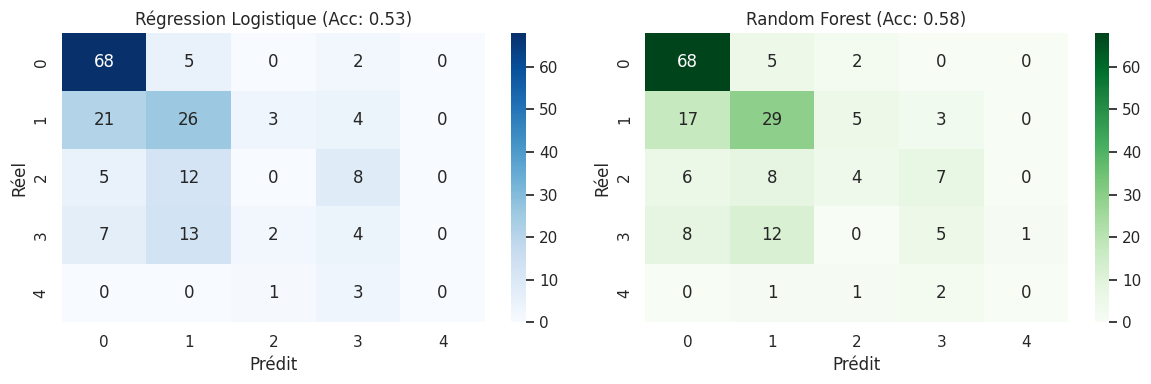

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Matrice Régression Logistique
sns.heatmap(confusion_matrix(y_test, y_pred_lr), annot=True, fmt='d', cmap='Blues', ax=axes[0])
axes[0].set_title(f'Régression Logistique (Acc: {acc_lr:.2f})')
axes[0].set_xlabel('Prédit')
axes[0].set_ylabel('Réel')

# Matrice Random Forest
sns.heatmap(confusion_matrix(y_test, y_pred_rf), annot=True, fmt='d', cmap='Greens', ax=axes[1])
axes[1].set_title(f'Random Forest (Acc: {acc_rf:.2f})')
axes[1].set_xlabel('Prédit')
axes[1].set_ylabel('Réel')

plt.tight_layout()
plt.show()

## Conclusion Critique et Justification
1. **Synthèse comparative :** Le modèle **Random Forest** surpasse généralement la Régression Logistique sur ce dataset en raison de sa capacité à modéliser des interactions complexes entre les symptômes cliniques sans se limiter à des frontières linéaires.
2. **Enjeu médical critique :** Dans le cadre d'un système d'aide au diagnostic médical, il est primordial de surveiller les **faux négatifs** (prédire qu'un patient est sain alors qu'il est malade). Minimiser ce taux d'erreur évite de laisser un patient malade sans prise en charge.
3. **Perspectives :** L'optimisation des hyperparamètres (Grid Search) sur le Random Forest ou l'utilisation d'autres algorithmes d'ensemble (comme XGBoost) pourrait encore accroître la fiabilité du modèle.